# 06 — Practical Guide

Five notebooks of evidence, collected into decisions you can apply on Monday.

This notebook reads the JSON results written by notebooks 01–05, so every number below is
the measured one, not a remembered one. Run the earlier notebooks first.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from src.config import load_settings
from src.reporting import load_results, save_results
from src.visualisation import plot_summary_table, save_figure

settings = load_settings()

nb01 = load_results("01_what_random_really_means")
nb02 = load_results("02_sampling_from_any_distribution")
nb03 = load_results("03_when_your_sample_is_biased")
nb04 = load_results("04_monte_carlo")
nb05 = load_results("05_importance_sampling")

print("loaded results from notebooks 01-05")
print(f"project seed = {settings.seed}")

loaded results from notebooks 01-05
project seed = 20260909


## The scoreboard

Every claim this project makes, with the number that backs it.

  A broken generator passes a uniformity test   RANDU chi-square p = 0.257
  ...and fails a structure test                 100% of triples on 15 planes
  Inverse transform matches its target          KS p = 0.732
  Rejection acceptance rate equals 1/m          0.312 vs 0.313
  Stratifying cuts variance at no extra cost    6.9x lower
  Neyman allocation does better still           28.2x lower
  Selection bias survives more data             converges to 66.1, truth 52.7
  Random row splits leak entities               100% vs 0% group-aware
  Monte Carlo error falls as n^-1/2             fitted slope -0.517
  Brute force cannot see a 1e-7 event           0 events in 1,000,000 draws
  Importance sampling recovers it cheaply       +4.4% from 5,000 draws
  A bad proposal is much worse                  27x more variable
! Light-tailed proposal fails at practical n    sd 0.020 vs 0.034


/workspaces/sampling_101/outputs/figures/06_summary_table.png


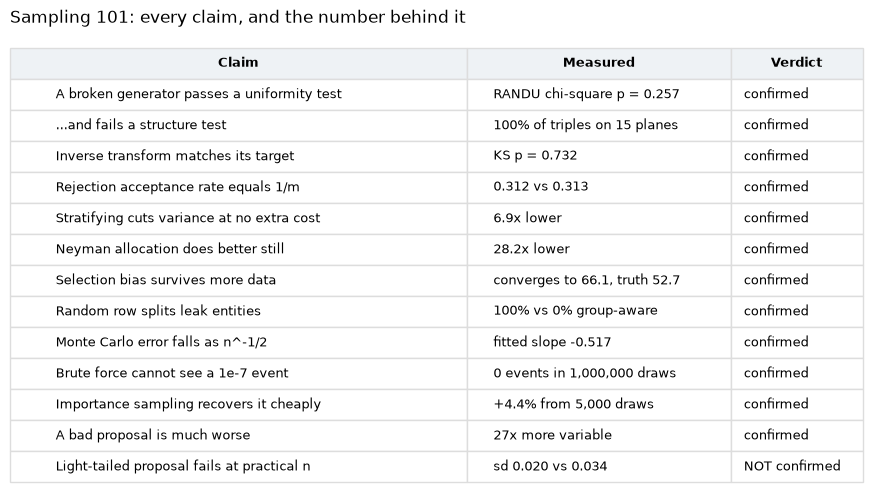

In [2]:
randu = nb01["generators"]["RANDU"]
designs = nb03["designs"]
good = nb05["good_proposal"]
bad = nb05["bad_proposal"]

rows = [
    (
        "A broken generator passes a uniformity test",
        f"RANDU chi-square p = {randu['chi_square_p']:.3f}",
        "confirmed",
    ),
    (
        "...and fails a structure test",
        f"{randu['plane_fraction']:.0%} of triples on {randu['plane_count']} planes",
        "confirmed",
    ),
    (
        "Inverse transform matches its target",
        f"KS p = {nb02['inverse_transform']['normal_numeric_grid']['ks_p_value']:.3f}",
        "confirmed",
    ),
    (
        "Rejection acceptance rate equals 1/m",
        f"{nb02['rejection']['empirical_acceptance_rate']:.3f} vs "
        f"{nb02['rejection']['theoretical_acceptance_rate']:.3f}",
        "confirmed",
    ),
    (
        "Stratifying cuts variance at no extra cost",
        f"{designs['stratified_proportional']['variance_reduction_vs_simple']:.1f}x lower",
        "confirmed",
    ),
    (
        "Neyman allocation does better still",
        f"{designs['stratified_neyman']['variance_reduction_vs_simple']:.1f}x lower",
        "confirmed",
    ),
    (
        "Selection bias survives more data",
        f"converges to {nb03['selection_bias']['more_data_does_not_help']['frame_limit']:.1f}, "
        f"truth {nb03['true_mean']:.1f}",
        "confirmed",
    ),
    (
        "Random row splits leak entities",
        f"{nb03['grouped_data']['leakage_random_row_split']:.0%} vs "
        f"{nb03['grouped_data']['leakage_group_aware_split']:.0%} group-aware",
        "confirmed",
    ),
    (
        "Monte Carlo error falls as n^-1/2",
        f"fitted slope {nb04['convergence']['fitted_log_log_slope']:.3f}",
        "confirmed",
    ),
    (
        "Brute force cannot see a 1e-7 event",
        f"0 events in {nb05['brute_force']['n_draws']:,} draws",
        "confirmed",
    ),
    (
        "Importance sampling recovers it cheaply",
        f"{good['relative_error']:+.1%} from {good['n_draws']:,} draws",
        "confirmed",
    ),
    (
        "A bad proposal is much worse",
        f"{bad['times_worse_than_good']:.0f}x more variable",
        "confirmed",
    ),
    (
        "Light-tailed proposal fails at practical n",
        f"sd {nb05['light_tailed_proposal_footnote']['replicate_relative_sd']:.3f} vs "
        f"{good['replicate_relative_sd']:.3f}",
        "NOT confirmed",
    ),
]

for claim, measured, verdict in rows:
    flag = " " if verdict == "confirmed" else "!"
    print(f"{flag} {claim:<45} {measured}")

fig = plot_summary_table(rows, "Sampling 101: every claim, and the number behind it")
print(save_figure(fig, "06_summary_table"))

Note the last row. One claim this project set out to demonstrate did **not** survive
measurement: the textbook warning that a light-tailed proposal ruins importance sampling
is true asymptotically and invisible at any sample size you would actually use. It is
recorded as not confirmed rather than quietly dropped.

## Decision guide 1: sampling and splitting data

**Always ask: random with respect to what?**

In [3]:
guide_sampling = {
    "Rare or important subgroup that must be represented": "Stratify on it",
    "Rows nest inside entities (users, patients, sites)": "Split and sample by entity",
    "Subgroup variances differ a lot and sampling is costly": "Neyman allocation",
    "Not everyone in the population could be sampled": "Fix the frame; no estimator saves you",
    "Response depends on the thing being measured": "Reweight, or accept a biased answer",
    "None of the above": "Simple random is fine, and report the standard error",
}

for situation, action in guide_sampling.items():
    print(f"{situation:<52} -> {action}")

Rare or important subgroup that must be represented  -> Stratify on it
Rows nest inside entities (users, patients, sites)   -> Split and sample by entity
Subgroup variances differ a lot and sampling is costly -> Neyman allocation
Not everyone in the population could be sampled      -> Fix the frame; no estimator saves you
Response depends on the thing being measured         -> Reweight, or accept a biased answer
None of the above                                    -> Simple random is fine, and report the standard error


Three rules that follow from notebook 03:

1. **Unbiased is not the same as precise.** Simple random sampling was unbiased in every
   experiment and still the worst design available.
2. **Stratification removes variance, not bias.** It is not a repair for a broken frame.
3. **More data cannot fix selection bias.** It tightens the interval around the wrong
   number: in notebook 03 the biased estimator converged to a computable frame limit that
   is nowhere near the population mean, and the printout above shows both.

## Decision guide 2: computing things

In [4]:
guide_computing = {
    "Integral with no closed form": "Monte Carlo: sample, evaluate, average",
    "High-dimensional integral": "Monte Carlo (the rate does not depend on dimension)",
    "Expectation of an ugly function": "Monte Carlo with the same three lines",
    "Probability of a common event": "Monte Carlo",
    "Probability of a rare event": "Importance sampling, proposal centred on the event",
    "Need 10x more accuracy": "Budget 100x the samples",
}

for problem, method in guide_computing.items():
    print(f"{problem:<45} -> {method}")

Integral with no closed form                  -> Monte Carlo: sample, evaluate, average
High-dimensional integral                     -> Monte Carlo (the rate does not depend on dimension)
Expectation of an ugly function               -> Monte Carlo with the same three lines
Probability of a common event                 -> Monte Carlo
Probability of a rare event                   -> Importance sampling, proposal centred on the event
Need 10x more accuracy                        -> Budget 100x the samples


### The cost of accuracy

The single most useful number from notebook 04:

In [5]:
slope = nb04["convergence"]["fitted_log_log_slope"]
print(f"measured error rate: n^{slope:.3f}   (theory: n^-0.5)\n")
print("accuracy wanted    samples needed")
for factor in (2, 10, 100):
    print(f"{factor:>10}x       {factor**2:>12,}x")

measured error rate: n^-0.517   (theory: n^-0.5)

accuracy wanted    samples needed
         2x                  4x
        10x                100x
       100x             10,000x


## Decision guide 3: choosing a sampler

In [6]:
guide_samplers = {
    "CDF invertible in closed form": "Inverse transform (exact, no waste)",
    "Density known, CDF is not": "Inverse transform on a numeric grid",
    "Density evaluable but hard to integrate": "Rejection sampling (costs 1/m)",
    "Repeated draws from fixed categories": "Alias table (O(1) per draw)",
    "Density known only up to a constant": "Rejection or self-normalised importance sampling",
}

for situation, method in guide_samplers.items():
    print(f"{situation:<42} -> {method}")

CDF invertible in closed form              -> Inverse transform (exact, no waste)
Density known, CDF is not                  -> Inverse transform on a numeric grid
Density evaluable but hard to integrate    -> Rejection sampling (costs 1/m)
Repeated draws from fixed categories       -> Alias table (O(1) per draw)
Density known only up to a constant        -> Rejection or self-normalised importance sampling


## The reproducibility rule

Underlying all of it, and the cheapest habit in this list:

> **Seed everything, and record the seed.** A "random" result you cannot reproduce is not
> a result.

In [7]:
print("Do:")
print("  rng = np.random.default_rng(seed)      # explicit generator, passed around")
print("  sample = my_function(data, rng=rng)    # dependency, not global state")
print("\nDo not:")
print("  np.random.seed(42)                     # legacy global state")
print("  np.random.rand(100)                    # which stream did this consume?")
print(f"\nEvery figure in this repo comes from seed {settings.seed}, stored in")
print("config/settings.yaml. Re-running any notebook reproduces them exactly.")

Do:
  rng = np.random.default_rng(seed)      # explicit generator, passed around
  sample = my_function(data, rng=rng)    # dependency, not global state

Do not:
  np.random.seed(42)                     # legacy global state
  np.random.rand(100)                    # which stream did this consume?

Every figure in this repo comes from seed 20260909, stored in
config/settings.yaml. Re-running any notebook reproduces them exactly.


## The tools you leave with

Everything demonstrated here is tested library code, not notebook scratch.

In [8]:
tools = {
    "src.generators.quality": "chi_square_uniformity, plane_fraction - test a generator",
    "src.draw.inverse_transform": "numeric_inverse_cdf - sample any density you can write",
    "src.draw.rejection": "rejection_sample - with an envelope check that raises",
    "src.draw.discrete": "AliasTable - O(1) weighted categorical draws",
    "src.survey.stratified": "stratified_mean - proportional and Neyman allocation",
    "src.survey.grouped": "group_train_test_split, group_leakage_rate - entity-safe splits",
    "src.survey.bias": "frame_limit_mean - what a biased frame converges to",
    "src.montecarlo.integration": "integrate, expectation - estimate with standard errors",
    "src.montecarlo.importance": "importance_estimate - rare events, with diagnostics",
    "src.evaluation.convergence": "fit_convergence_rate - measure your own error rate",
}

for module, what in tools.items():
    print(f"{module:<30} {what}")

src.generators.quality         chi_square_uniformity, plane_fraction - test a generator
src.draw.inverse_transform     numeric_inverse_cdf - sample any density you can write
src.draw.rejection             rejection_sample - with an envelope check that raises
src.draw.discrete              AliasTable - O(1) weighted categorical draws
src.survey.stratified          stratified_mean - proportional and Neyman allocation
src.survey.grouped             group_train_test_split, group_leakage_rate - entity-safe splits
src.survey.bias                frame_limit_mean - what a biased frame converges to
src.montecarlo.integration     integrate, expectation - estimate with standard errors
src.montecarlo.importance      importance_estimate - rare events, with diagnostics
src.evaluation.convergence     fit_convergence_rate - measure your own error rate


### A worked example of the whole toolkit

One cell: build a biased-frame problem, measure the damage, and fix the design.

In [9]:
from src.datasets.populations import response_propensity, skewed_population
from src.survey.bias import frame_limit_mean, response_biased_mean
from src.survey.simple import simple_random_mean
from src.survey.stratified import stratified_mean

rng = np.random.default_rng(settings.seed)
cfg = settings.survey
pop = skewed_population(
    cfg.population_size, cfg.strata_proportions, cfg.strata_means, cfg.strata_sds, rng
)

propensity = response_propensity(pop.values, cfg.response_strength)
biased = response_biased_mean(pop.values, propensity, 1000, rng)
srs = simple_random_mean(pop.values, 1000, rng)
strat = stratified_mean(pop.values, pop.strata, 1000, rng, allocation="neyman")

print(f"truth                     {pop.true_mean:8.4f}")
print(f"biased frame              {biased.estimate:8.4f}  (converges to "
      f"{frame_limit_mean(pop.values, propensity):.4f}, never to the truth)")
print(f"simple random             {srs.value:8.4f} +/- {srs.se:.4f}")
print(f"stratified, Neyman        {strat.value:8.4f} +/- {strat.se:.4f}  <- same cost, "
      f"{srs.se / strat.se:.1f}x tighter")

truth                      52.6832
biased frame               70.2221  (converges to 66.0949, never to the truth)
simple random              53.4483 +/- 2.2808
stratified, Neyman         52.7554 +/- 0.4806  <- same cost, 4.7x tighter


## Saving the results

In [10]:
results = {
    "notebook": "06_practical_guide",
    "seed": settings.seed,
    "scoreboard": [
        {"claim": claim, "measured": measured, "verdict": verdict}
        for claim, measured, verdict in rows
    ],
    "claims_confirmed": sum(1 for _, _, v in rows if v == "confirmed"),
    "claims_not_confirmed": sum(1 for _, _, v in rows if v != "confirmed"),
    "decision_guides": {
        "sampling_and_splitting": guide_sampling,
        "computing": guide_computing,
        "choosing_a_sampler": guide_samplers,
    },
    "headline_numbers": {
        "randu_plane_fraction": randu["plane_fraction"],
        "randu_plane_count": randu["plane_count"],
        "stratified_variance_reduction": designs["stratified_proportional"][
            "variance_reduction_vs_simple"
        ],
        "neyman_variance_reduction": designs["stratified_neyman"][
            "variance_reduction_vs_simple"
        ],
        "row_split_leakage": nb03["grouped_data"]["leakage_random_row_split"],
        "monte_carlo_slope": slope,
        "rare_event_truth": nb05["truth"],
        "brute_force_estimate": nb05["brute_force"]["estimate"],
        "brute_force_draws": nb05["brute_force"]["n_draws"],
        "importance_estimate": good["estimate"],
        "importance_draws": good["n_draws"],
        "importance_relative_error": good["relative_error"],
    },
    "worked_example": {
        "truth": pop.true_mean,
        "biased_frame_estimate": biased.estimate,
        "frame_limit": frame_limit_mean(pop.values, propensity),
        "simple_random": {"value": srs.value, "se": srs.se},
        "stratified_neyman": {"value": strat.value, "se": strat.se},
        "se_improvement": float(srs.se / strat.se),
    },
    "rules": [
        "Ask 'random with respect to what?' before every split and every sample.",
        "Stratify on what matters; group by entity; interrogate the frame.",
        "Unbiased is not precise, and more data cannot fix selection bias.",
        "Monte Carlo turns intractable computation into sample-and-average, at n^-1/2.",
        "Importance sampling reaches events brute force never will, if the proposal covers them.",
        "Check diagnostics, not point estimates.",
        "Seed everything and record the seed.",
    ],
    "figures": ["06_summary_table"],
}
print(save_results("06_practical_guide", results))

/workspaces/sampling_101/outputs/results/06_practical_guide.json


## The whole project in six lines

1. **Random is a property to verify**, not assume. A generator can pass every obvious test
   and still be unusable.
2. **The library one-liners are ten lines of code** you now know: invert a CDF, or propose
   and accept.
3. **Convenient sampling is biased sampling.** Ask what the randomness is with respect to,
   stratify on what matters, and group by entity.
4. **Hard computation is darts and counting**, at a cost of $1/\sqrt{n}$.
5. **Rare events need importance sampling**, and the proposal is the method.
6. **Seed everything.**

### Where to go next

- **Bootstrap**: resampling your own data to get a confidence interval — a special case
  of the sampling ideas here.
- **MCMC**: sampling from a distribution you can only evaluate, which is how Bayesian
  posteriors are computed.
- **Quasi-Monte Carlo**: low-discrepancy sequences that beat the $1/\sqrt{n}$ rate.
- **Variance reduction**: control variates and antithetic variates.
- **Reservoir sampling**: a fair sample from a stream too large to store.